# Este Notebook es para ciertas cosas que nos referimos dentro del informe final! :)

## **Paso 3– preprocesamiento del texto**


#### ***Carga de los datos***

Primero importamos las librerias que utilizaremos durante el trabajo y cargamos nuestro corpus

Antes de realizar alguna modificación, creamos una copia de los datos para conservar el DataFrame original y asi evitar perder información durante el preprocesamiento

In [1]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

import matplotlib.pyplot as plt  # es para la parte 6++*

# cargamos los datos originales
df_original = pd.read_csv("../data/bbc_data.csv")

# creamos una copia para trabajar
df = df_original.copy()

# guardamos la copia en la carpeta data
df.to_csv("../data/bbc_data_copia.csv", index = False)


### ***Limpieza de los datos***

- Antes de trabajar con el contenido de las noticias revisamos
si existen valores nulos o documentos repetidos. Decidimos eliminar estos registros para evitar que una misma noticia
tenga mayor influencia en nuestro analisis por aparecer mas de una vez

In [2]:
# revisamos los datos antes de limpiarlos
print("Documentos originales:", len(df))
print("Valores nulos:", df.isnull().sum().sum())
print("Documentos duplicados:", df.duplicated(subset = ["data"]).sum())

# eliminamos valores nulos y noticias repetidas
df = df.dropna(subset = ["data", "labels"])
df = df.drop_duplicates(subset = ["data"])
df = df.reset_index(drop = True)

# guardamos los cambios en nuestra copia
df.to_csv("../data/bbc_data_copia.csv", index = False)

print("Documentos eliminados:", len(df_original) - len(df))
print("Documentos finales:", len(df))

Documentos originales: 2225
Valores nulos: 0
Documentos duplicados: 99
Documentos eliminados: 99
Documentos finales: 2126


### ***Separación de documentos y categorias***

- Separamos el contenido de las noticias de sus respectivas categorias, ya que para construir nuestra matriz solamente necesitamos trabajar con el texto
- Las categorias las guardaremos para mas adelante comparar los resultados obtenidos mediante SVD

In [3]:
# separamos las noticias de sus categorias
documentos = df["data"].tolist()
categorias = df["labels"].to_numpy()

print("Cantidad de documentos:", len(documentos))
print("Categorias:", np.unique(categorias))

Cantidad de documentos: 2126
Categorias: ['business' 'entertainment' 'politics' 'sport' 'tech']



Nos permite realizar el analisis sin utilizar las categorias, ya que nuestra idea es observar si las noticias  se agrupan por si solas segun su contenido

### ***Preprocesamiento y TF-IDF***

Para construir nuestro vocabulario necesitamos quedarnos con las palabras que sean mas relevantes para nuestro analisis

para esto decidimos:

- Convertir todas las palabras a minusculas
- Separar los textos en palabras de al menos dos letras
- Eliminar las stopwords del ingles
- Eliminar palabras que aparecen en menos de 3 documentos
- Eliminar palabras que aparecen en mas del 85% de los documentos

Utilizamos TF-IDF en lugar de trabajar directamente con la frecuencia de las palabras, porque nos permite darle mayor importancia a las que ayudan a diferenciar las noticias

Tambien utilizamos la normalización L2 para que las diferencias en la longitud de las noticias tengan menos influencia en el analisis

In [4]:
# configuramos TF-IDF
vectorizador = TfidfVectorizer(
    lowercase = True,
    stop_words = "english",
    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b",
    min_df = 3,
    max_df = 0.85,
    norm = "l2"
)

# aplicamos TF-IDF a las noticias
X = vectorizador.fit_transform(documentos)

# obtenemos nuestro vocabulario
vocabulario = vectorizador.get_feature_names_out()

print("Tamaño del vocabulario:", len(vocabulario))
print("Primeras 20 palabras:")
print(vocabulario[:20])

Tamaño del vocabulario: 12369
Primeras 20 palabras:
['aaa' 'aaas' 'aaron' 'abandon' 'abandoned' 'abandoning' 'abandonment'
 'abba' 'abbas' 'abbasi' 'abbott' 'abc' 'aberdeen' 'abeyie' 'abide'
 'abiding' 'abilities' 'ability' 'able' 'abn']


Luego de aplicar TF-IDF obtenemos nuestro vocabulario final compuesto por 12369 palabras que cumplen los criterios que definimos anteriormente

La idea de realizar este preprocesamiento es quedarnos con las palabras que realmente nos aportan información ya que esperamos que las noticias de una misma categoria tengan palabras en comun

## **Paso 4 – Construcción de la matriz textual**

### ***Construcción de la matriz A***

Ahora que tenemos nuestro vocabulario y los valores de TF-IDF podemos construir la matriz con la que trabajaremos

Como scikit-learn nos entrega los documentos en las filas y las palabras en las columnas, tenemos que transponer la matriz para obtener lo que nos pide el enunciado

**A pertenece R^(mxn)**

Donde:

- $m$: cantidad de palabras de nuestro vocabulario
- $n$: cantidad de noticias
- Cada entrada de A corresponde al peso TF-IDF de una palabra dentro de una noticia

In [5]:
# transponemos la matriz
A = X.T.tocsr()

# obtenemos sus dimensiones
m, n = A.shape

print("Dimensiones de A:", A.shape)
print("Cantidad de terminos:", m)
print("Cantidad de documentos:", n)
print("Entradas distintas de cero:", A.nnz)

Dimensiones de A: (12369, 2126)
Cantidad de terminos: 12369
Cantidad de documentos: 2126
Entradas distintas de cero: 278822


- Ya tenemos nuestra matriz A con las palabras en las filas y las noticias en las columnas

- Como no todas las palabras aparecen en todas las noticias, gran parte de nuestra matriz esta compuesta por ceros. Por esto decidimos trabajar con una matriz dispersa, para asi evitar almacenar todos estos ceros de manera innecesaria


### ***Visualización de la matriz***

Como la matriz es bastante grande, solo mostraremos las 10 palabras con mayor peso TF-IDF acumulado en los primeros 5 documentos para asi tener una idea de como quedo construida

In [6]:
# seleccionamos las 10 palabras con mayor peso
indices = np.argsort( A[:, :5].toarray().sum(axis = 1))[-10:][::-1]

# mostramos una parte de nuestra matriz
pd.DataFrame(A[indices, :5].toarray(), index = vocabulario[indices], columns = ["Doc 1", "Doc 2", "Doc 3", "Doc 4", "Doc 5"]).round(4)

,Doc 1,Doc 2,Doc 3,Doc 4,Doc 5
oceans,0.0000,0.0000,0.0000,0.2355,0.4769
musicians,0.5005,0.0000,0.0000,0.0000,0.0000
doherty,0.0000,0.0000,0.4735,0.0000,0.0000
carrey,0.0000,0.0000,0.0000,0.4711,0.0000
sequel,0.0000,0.0000,0.0000,0.0000,0.3604
band,0.0000,0.3002,0.0513,0.0000,0.0000
starring,0.0000,0.0000,0.0000,0.1580,0.1919
number,0.0000,0.0669,0.0305,0.1698,0.0688
chart,0.0000,0.0405,0.0000,0.2314,0.0625
box,0.0000,0.0000,0.0000,0.1390,0.1689


- Podemos observar que cuando una palabra no aparece en una noticia, su valor es 0, en caso contrario tenemos el peso que le asigno TF-IDF

- De esta manera pasamos de tener noticias en formato de texto a tener una representación numerica

## **Paso 5 – Calculo de la SVD**

### ***Descomposición en valores singulares***

Ahora que tenemos la matriz A podemos aplicar la descomposición SVD

Recordemos que A = U · Σ · Vᵀ

Donde:
- U: contiene los vectores singulares izquierdos
- Σ: matriz diagonal que contiene los valores singulares
- V: contiene los vectores singulares derechos

Utilizaremos NumPy con el parametro `full_matrices=False`, ya que no necesitamos almacenar vectores adicionales para representar nuestra matriz

Tambien debemos pasar nuestra matriz dispersa a una matriz densa para poder utilizar este metodo

In [7]:
# calculamos la SVD de nuestra matriz A
U, s, Vt = np.linalg.svd( A.toarray(), full_matrices = False)

# obtenemos Sigma y V
Sigma = np.diag(s)
V = Vt.T

# mostramos las dimensiones
print("Dimensiones de A:", A.shape)
print("Dimensiones de U:", U.shape)
print("Dimensiones de Sigma:", Sigma.shape)
print("Dimensiones de V:", V.shape)
print("Cantidad de valores singulares:", len(s))

Dimensiones de A: (12369, 2126)
Dimensiones de U: (12369, 2126)
Dimensiones de Sigma: (2126, 2126)
Dimensiones de V: (2126, 2126)
Cantidad de valores singulares: 2126


Luego de aplicar SVD obtenemos las matrices U, Σ y V, con las cuales podemos representar nuestra matriz A

Si consideramos r = min(m,n), las dimensiones de nuestras matrices quedan de la siguiente manera:


Si consideramos r = min(m,n), las dimensiones de nuestras
matrices quedan de la siguiente manera:

- A: 12369 x 2126
- U: 12369 x 2126
- Σ: 2126 x 2126
- V: 2126 x 2126

La idea de realizar esta descomposición es que mas adelante podamos trabajar con menos componentes sin perder demasiada información de nuestra matriz

Con esto podremos analizar si las noticias se agrupan segun su contenido, como planteamos en nuestra hipotesis inicial

### ***Valores singulares***

Antes de decidir con cuantas componentes nos quedaremos veamos los primeros 10 valores singulares que obtuvimosal aplicar SVD

In [8]:
# mostramos los primeros 10 valores singulares
print(s[:10])

[7.54445398 4.79812001 4.32966286 4.08820491 3.89337884 3.40298315
 3.14515989 3.08270004 3.04091875 2.95077703]


Podemos observar que los valores singulares estan ordenados de mayor a menor. Mientras mayor sea el valor singular, mayor sera el aporte de su componente a la información de nuestra matriz, medido a traves de la norma de Frobenius. Por ahora nos quedaremos con todos los valores singulares, porque en el siguiente paso veremos cuantos nos conviene utilizar

### ***Verificación de la SVD***

Para ver si realizamos correctamente la descomposición, reconstruiremos una pequeña parte de nuestra matriz A y la compararemos con la original. La idea es calcular la norma de la diferencia entre ambas matrices y obtener un error lo mas cercano posible a 0

In [9]:
# tomamos una parte de nuestra matriz original
A_original = A[:10, :10].toarray()

# reconstruimos la misma parte utilizando SVD
A_reconstruida = U[:10, :] @ Sigma @ Vt[:, :10]

# calculamos el error con la norma de Frobenius
error = np.linalg.norm(A_original - A_reconstruida, ord = "fro")

print("Error de reconstrucción:", error)

print("Reconstrucción correcta:", np.allclose(A_original, A_reconstruida))

Error de reconstrucción: 4.2554158411964895e-16
Reconstrucción correcta: True


Logramos reconstruir correctamente la parte de la matriz que seleccionamos, obteniendo un error de 4.67e-16, el cual es practicamente 0

### ***Analisis de valores singulares***

[ENUNCIADO] Analicen cu ́anto de la estructura del problema se concentra en pocas componentes. Grafiquen los valores singulares, observen su decaimiento y elijan un valor razonable de k para una representaci ́on reducida. Justifiquen brevemente la elecci ́on de k.


# Analicen cu ́anto de la estructura del problema se concentra en pocas componentes.

En nuestra corpus la energia no se concentra en pocas componentes, la primera retiene un 2.7% (0.027) y las primeras 5 retienen el 6.1& y las otras 100 un 26.6%

Para retener el 50.0 % de la energia se necesitan k = 351 componentes

Para retener el 75.0 % de la energia se necesitan k = 830 componentes

Para retener el 90.0 % de la energia se necesitan k = 1337 componentes

Es decir la informacion esta repartida entre muchas componentes, aun asi los valores singulares decaen muy rapido al inicio: sigma_1 aprox= 7.54 y sigma_5 aprox= 3.89 (7.54 4.79 4.32 4.08 3.89 ... 2.95) acomparacion de los valores que toman los valores singulares apartir de un valor de 3. Esto indica que unas pocas componentes capturan la estructura mas general de la corpus y que el resto meramente describe variaciones mas especificas en cada noticia



# Grafiquen los valores singulares, observen su decaimiento y elijan un valor razonable de k para una representaci ́on reducida. Justifiquen brevemente la elecci ́on de k.

Los valores singulares decaen rapido al inicio y despues lo hacen cada vez mas lento, entonces, se puede notar un cambio de "comportamiento" entre el sigma 5 y el sigma 6 (sigma_5 - sigma_6 = 0.49) el cual es mayor a las caidas de sus vecinas (sigma_4 - sigma_5 = 0.19 // sigma_6 - sigma_7 = 0.26) y apartir de sigma 7 las caidas ya son muy chicas.

Es por ello que elegimos un k = 5, este valor se justifica meramente por el cambio de decaimiento y por la interpretabilidad que se le dara en el siguiente paso (el 7)

Las primeras componentes nos permiten separar las noticias por temas y al usamos un k = 5 para explorar la estructura del corpus y mostrarla en vez de recostruirla

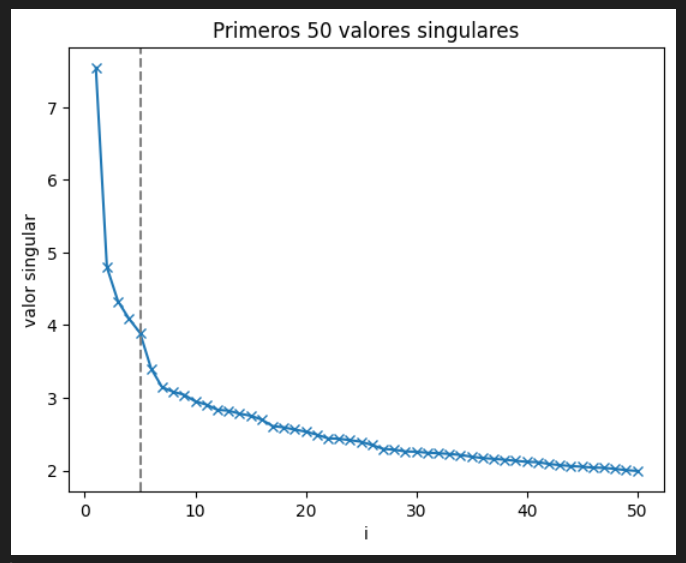

      k  Energia retenida  Error relativo
0     1             0.027           0.987
1     2             0.038           0.981
2     3             0.046           0.977
3     4             0.054           0.972
4     5             0.061           0.969
5     6             0.067           0.966
6    10             0.084           0.957
7    15             0.103           0.947
8    20             0.119           0.939
9    30             0.145           0.924
10   40             0.168           0.912
11   50             0.188           0.901
12  100             0.266           0.857
13  200             0.377           0.789


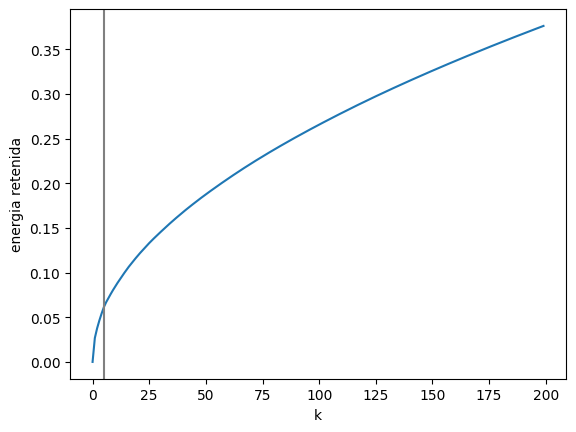

In [10]:
total = np.sum(s**2)
valores_k = [1, 2, 3, 4, 5, 6, 10, 15, 20, 30, 40, 50, 100, 200]

energias = []
errores = []

for k in valores_k:
    energia_retenida = np.sum(s[:k]**2) / total

    error_relativo = np.sqrt(np.sum(s[k:]**2) / total)

    energias.append(energia_retenida)
    errores.append(error_relativo)

# armamos una tabla con lo que salio
tabla = pd.DataFrame({
    "k": valores_k,
    "Energia retenida": energias,
    "Error relativo": errores
})

print(tabla.round(3))

# grafico de la energia retenida segun k, con una linea en el k elegido
k_elegido = 5

kas = []
for i in range(0, 200):
  kas.append(i)

retenida = []
for k in kas:
    retenida.append(np.sum(s[:k]**2) / total)

plt.plot(kas, retenida)
plt.axvline(k_elegido, linestyle="-", color="gray")
plt.xlabel("k")
plt.ylabel("energia retenida")
plt.show()

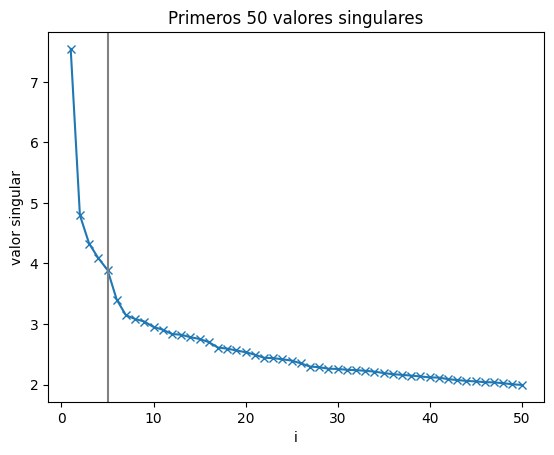

Para retener el 50.0 % de la energia se necesitan k = 351 componentes
Para retener el 75.0 % de la energia se necesitan k = 830 componentes
Para retener el 90.0 % de la energia se necesitan k = 1337 componentes
sigma_1 - sigma_2 = 2.75
sigma_2 - sigma_3 = 0.47
sigma_3 - sigma_4 = 0.24
sigma_4 - sigma_5 = 0.19
sigma_5 - sigma_6 = 0.49
sigma_6 - sigma_7 = 0.26
sigma_7 - sigma_8 = 0.06
sigma_8 - sigma_9 = 0.04
sigma_9 - sigma_10 = 0.09


In [11]:
asad = []
for uwu in range(1,51):
    asad.append(uwu)

plt.plot(asad ,s[:50], marker="x" ) 
plt.axvline(5, linestyle="-", color="gray")
plt.title("Primeros 50 valores singulares")
plt.xlabel("i")
plt.ylabel("valor singular")
plt.show()

total = np.sum(s**2) 
for p in [0.5, 0.75, 0.9] : 
    suma = 0
    k = 0
    for valor_singular in s:
        suma = suma + valor_singular**2 / total
        k = k + 1
        if suma >= p:
            break
    print(f"Para retener el {p*100} % de la energia se necesitan k = {k} componentes")

for i in range(1, 10):
    caida = s[i - 1] - s[i]
    print(f"sigma_{i} - sigma_{i+1} = {caida:.2f}")


### ***Representacion de documentos y terminos en baja dimension***

[ENUNCIADO] Usen pares de componentes de la SVD para construir representaciones
2D reducidas.


Para los t ́erminos, representados como filas de A, tienen que elegir un par
de vectores singulares va, vbpor la derecha y proyectar las filas de A en el plano
Span(va, vb), utilizando las coordenadas en la base va, vbpara una visualizaci ́on
2D de t ́erminos. Asimismo, para la visualizaci ́on 2D de documentos, tienen
que elegir un par de vectores ua, ubpor la izquierda y hacer una proyecci ́on
correspondiente


Expliquen brevemente la manera en que han calculado estas proyecciones en su c ́odigo.


Incluyan una visualizaci ́on 2D de documentos y una visualizaci ́on 2D de
palabras o t ́erminos relevantes, indicando qu ́e par de componentes usaron y por
qu ́e. 


***Pares de componentes de la SVD***

Como elegimos k = 5, con las 5 primeras componentes se pueden formar 10 pares distintos




***Las proyecciones de las Filas de A en el plano de span v_a v_b***

Cada documento es una columna de A y cada termino es una fila de A,

**Terminos (filas de A).** Proyectamos las filas de A sobre el plano Span(v_a, v_b), donde v_a y v_b son vectores singulares por la derecha. Las coordenadas son:

`(A * v_a, A * v_b) = (sigma_a * u_a, sigma_b * u_b)`

En el codigo usamos la segunda forma: `s[a] * U[:, a]` y `s[b] * U[:, b]`.

**Documentos (columnas de A).** Proyectamos las columnas de A sobre el plano Span(u_a, u_b), donde u_a y u_b son vectores singulares por la izquierda. Las coordenadas son:

`(u_a^T * A, u_b^T * A) = (sigma_a * v_a^T, sigma_b * v_b^T)`

En el codigo usamos la segunda forma: `s[a] * Vt[a, :]` y `s[b] * Vt[b, :]`.



mbas formas son equivalentes porque A * v_a = sigma_a * u_a y u_a^T * A = sigma_a * v_a^T.

**Nota sobre el codigo posible confusion respecto a como se obtienen las cordenadas.** 

Esto lo podemos hacer partiendo desde la formula de la SVD 

A = U * S * V^T

A * v_a = U * S * V^T * v_a

como los vectores singulares de la derecha son ortonormales entonces 

V^T * v_a = p_a

p_a es un pector que tiene un valor 1 en la posicion respectiva a la componente a y tiene ceros en el resto, asi se tiene :

A*v_a = U * S * e_a

Al multiplicar solo se seleccionan los correspondientes columnas y valor singular 

A*v_a = sigma_a * u_a

Pasa lo mismo para los vectores por la izquierda, solo que en vez de comenzar por A se comienza por su transpuesta (esto para seguir el mismo procedimiento con u_a iniciando con el U en vez del V)

**Eleccion de pares**
mediante los graficos elegimos la de los componentes 3 y 4. esto dado que al compararlas visualmente con el resto, este separa mejor las categorias y los documentos forman cinco ramas  (una por seccion de la bbc)

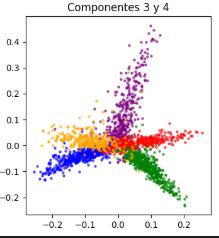

Para poder diferenciarlas bien, usamos colores para entender bien como se "contectan" y poder diferenciarlas de meros puntos en el grafico
ya que sin usarlos se ve asi 

colores = {"business": "blue", 
           "entertainment": "purple",
           "politics": "red",
           "sport": "green",
           "tech": "orange"}

 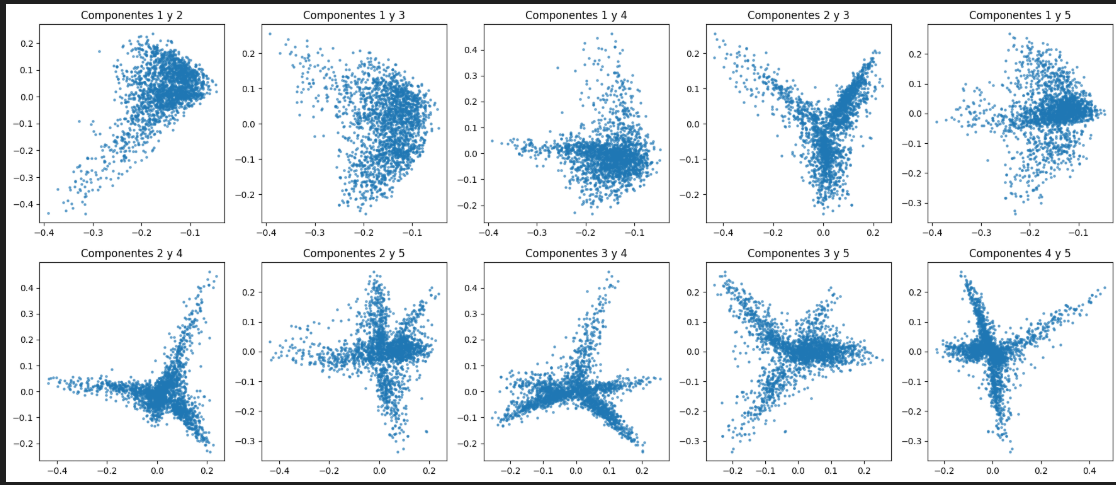



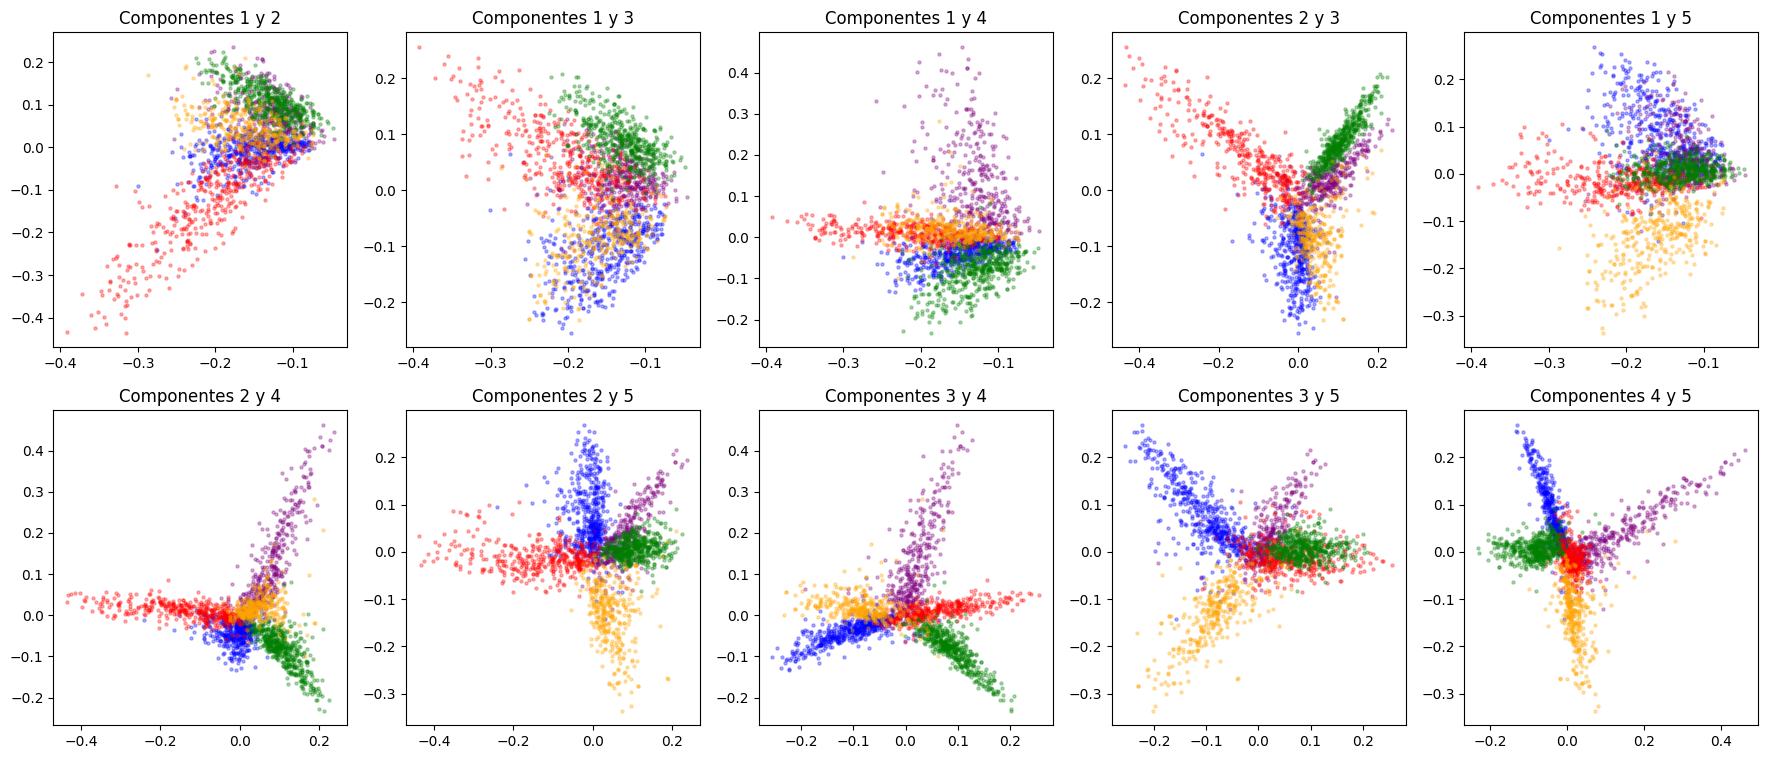

In [ ]:
 #V = Vt.T estos son los vectores singulares por la derecha
pares = [(1, 2), (1, 3), (1, 4), (2, 3), (1, 5), (2, 4), (2,5), (3, 4), (3, 5), (4, 5)]

fig, ejes = plt.subplots(2, 5, figsize=(22, 9))

ejes = ejes.flatten()

colores = {"business": "blue", 
           "entertainment": "purple",
           "politics": "red",
           "sport": "green",
           "tech": "orange"}


for n in range(len(pares)):
    a = pares[n][0] - 1
    b = pares[n][1] - 1

    coord_a = s[a] * Vt[a, :]
    coord_b = s[b] * Vt[b, :]

    for c in colores:
        mascara = categorias == c
        ejes[n].scatter(coord_a[mascara], coord_b[mascara], s=5 ,alpha=0.3, color=colores[c], label=c)
        # si le quitas el s=5 todo se ve dificil de ver pero se sigueentendiendo y el alpha es para poder visualizarlo un poco mejor
        # si le reduces el alpha como hasta 0.3 se visualiza un poco mejor elcomo se relacionan los temas
    ejes[n].set_title(f"Componentes {a + 1} y {b + 1}")



***Visualizacion 2D de terminos***
Proyectamos las filas de A sobre Span(v_3, v_4). Como hay muchos terminos, etiquetamos solo los 30 mas alejados del origen, que son los más relevantes para estas dos componentes.

// Aparte: Si quieres ver la mayor cantidad de palabras cambia la variable CANTIDAD_PALABRAS y te recomiendo muchisemo el cambiar el plt.figure(figsize=(10, 7)) en base al numero que coloques. para poder visualizarlo bien, usa este boton en el resultado

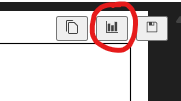

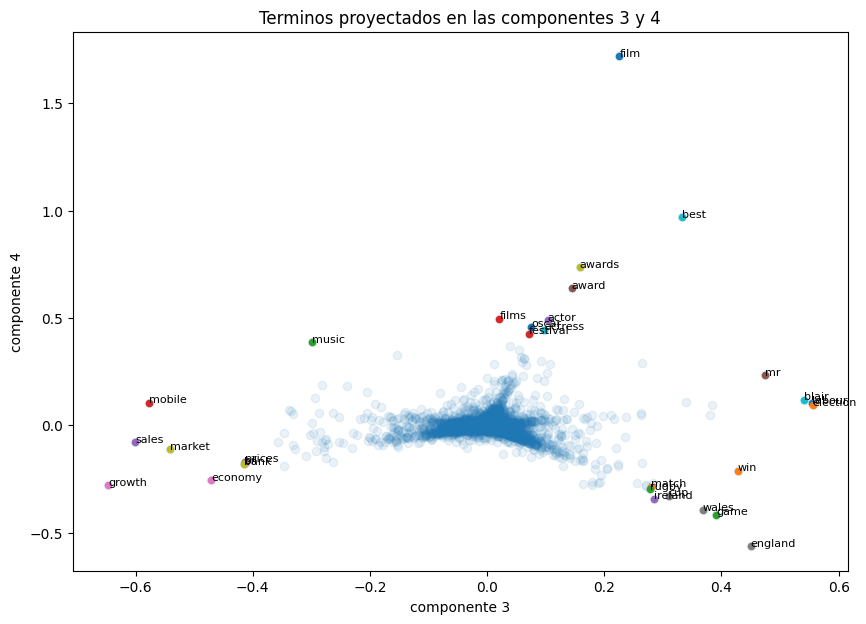

In [107]:
#vectores singulares por la izquierda 
u_a = U[:, 2]
u_b = U[:, 3]

CANTIDAD_PALABRAS = 30

#coordenadas de los terminos: (A v_a, A v_b) = (sigma_a u_a, sigma_b u_b)
terms_x = s[2] * u_a
terms_y = s[3] * u_b

#terminos relevantes son los 30 mas alejados del origen
normas = np.sqrt(terms_x**2 + terms_y**2)

pares_norma_index = []
for j in range(len(normas)):
    pares_norma_index.append((normas[j], j))
    
pares_norma_index.sort()

relevanteeee = []
for norma, j in pares_norma_index[-CANTIDAD_PALABRAS:]:
    relevanteeee.append(j)
    
plt.figure(figsize=(10, 7))
plt.scatter(terms_x, terms_y, alpha=0.09)

for j in relevanteeee:
    plt.scatter(terms_x[j], terms_y[j], s=20)
    plt.annotate(vocabulario[j], (terms_x[j], terms_y[j]), fontsize=8)

plt.xlabel(f"componente {3}")
plt.ylabel(f"componente {4}")
plt.title("Terminos proyectados en las componentes 3 y 4")
plt.show()

***Visualizacion 2D de documentos***
Proyectamos las columnas de A sobre Span u_3 u_4 e igual como antes los coloreamos

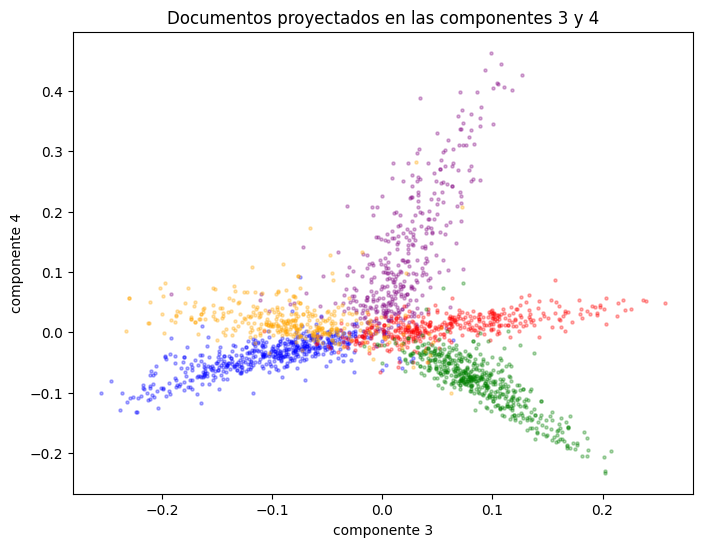

In [95]:
#vectores singulares por la derecha 
v_a = Vt[2, :]
v_b = Vt[3, :]

#coordenadas de los documentos: (u_a^T A, u_b^T A) = (sigma_a v_a^T, sigma_b v_b^T)
coord_a = s[a] * v_a
coord_b = s[b] * v_b

plt.figure(figsize=(8, 6))

for c in colores:
    mascara = categorias == c
    plt.scatter(coord_a[mascara], coord_b[mascara], s=5 ,alpha=0.3, color=colores[c], label=c)

plt.xlabel(f"componente {3}")
plt.ylabel(f"componente {4}")
plt.title("Documentos proyectados en las componentes 3 y 4")
plt.show()

**Interpretacion**

Para los **Documentos**, con los componentes 3 y 4 se forman 5 ramas donde se agrupan todas al medio, usando los colores 

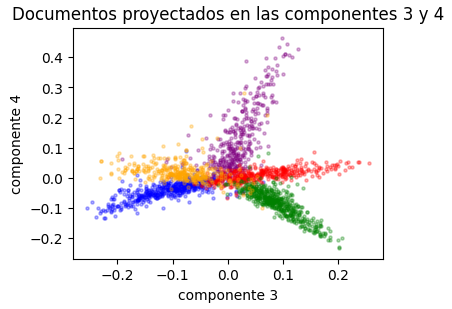

//Aparte: cambie el plt.figure(figsize=(8, 6)) a plt.figure(figsize=(4, 3)) para sacar la screenshot

colores = {"business": "blue", 

           "entertainment": "purple",

           "politics": "red",

           "sport": "green",

           "tech": "orange"}

notamos que las 2 ramas que estan mas unidas son la rama correspondiente a tecnologia se mezcla en parte con la de negocios y para lo mismo en el centro donde se mezclan todas


Para los **Terminos** las palabra mas alejadas del origen coinciden con las ramas de los documentos:

- entertainment : film best, awards, award, actor, films, festival
- politics : election, blair y algunas palabras que no entiendo.

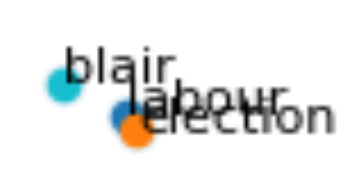

- sports : england, game, wales, win match, ireland
- business : growth, sales, market, economy, mobile, etc
- tech : music, Notar que como tech y business estan bastante cerca, estos hace sus palabras mas alejadas tambien coincidan en algunos casos, como en la siguiente imagen


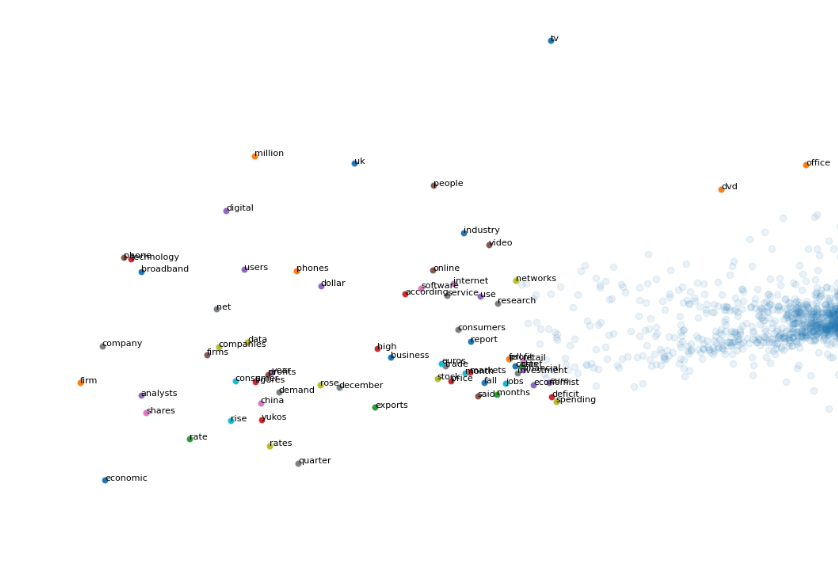

Podemos notar las separaciones entre business y sports, aun que hay puntos azules en la rama verde

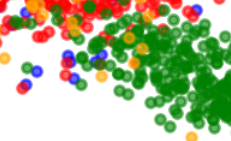


Ahora respecto a los componentes toman estos valores, (positivos o negativos) es meramente arbitrario y se deberia poder invertir al volver a calcular la SVD

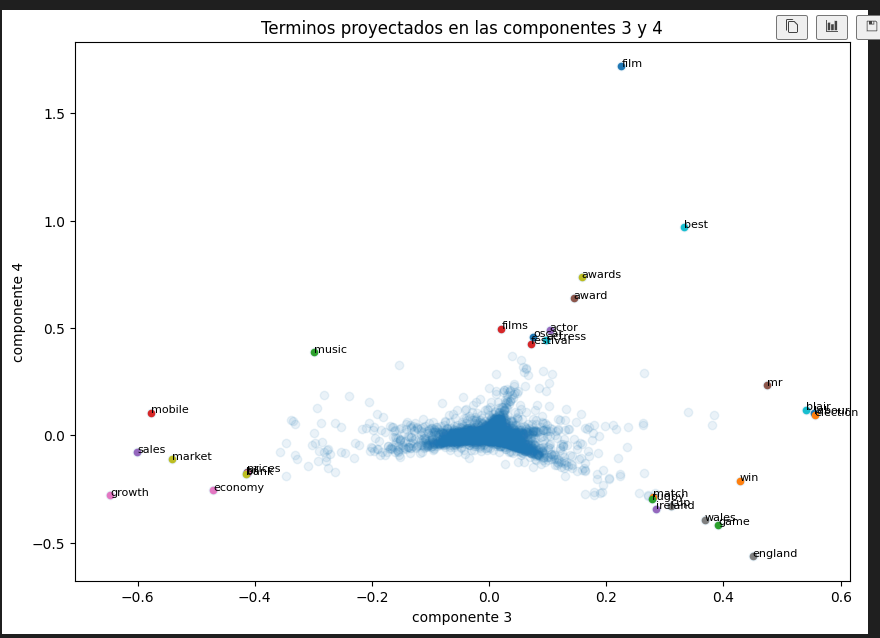